# TF-IDF (word + char) + MLP (spam w klasie pozytywnej)

Wariant `spam_1`: ogólny klasyfikator niechcianych wiadomości, więc phishing i spam należą do klasy pozytywnej (etykieta `label_spam_1`).

- **Cechy:** te same co w `tf_idf_xgb_spam_1`: TF-IDF na n-gramach słów (1-2) i znaków (3-5), po 100 000 najczęstszych n-gramów
  w każdym słowniku, a następnie selekcja chi-kwadrat. Liczba wybranych cech jest częścią grida.
- **Model:** sieć MLP w PyTorch (warstwy Linear, ReLU i Dropout), optymalizator AdamW, entropia krzyżowa, batch 256. Macierz rzadka
  jest zamieniana na gęstą po jednym batchu, na GPU.
- **Dobór hiperparametrów:** grid z k-fold CV na zbiorze treningowym. Foldy są rozłączne względem klastrów, a TF-IDF i selekcja cech są
  uczone osobno w każdym foldzie. Kryterium to AUCPR ważone odwrotnością rozmiaru klastra, a liczba epok jest dobierana
  wczesnym zatrzymaniem.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR ważonym klastrami nie większym niż 1%.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import itertools
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, WordCharTfidf, cluster_folds, cluster_weights, corpus_metrics, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)
from mlp_utils import DEVICE, n_parameters, predict, train_mlp

EXPERIMENT = "tf_idf_mlp_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

N_FOLDS = 3
FEATURE_COUNTS = (10_000, 20_000)
HIDDEN_LAYERS = ((256,), (512,), (512, 256))
DROPOUTS = (0.2, 0.5)
LEARNING_RATES = (1e-3, 3e-4)
WEIGHT_DECAYS = (1e-4, 1e-2)
MAX_EPOCHS = 30
PATIENCE = 3
SEED = 42
print("Urządzenie:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Urządzenie: cuda NVIDIA GeForce RTX 2080


## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


## Grid z k-fold CV

Liczba epok nie jest częścią siatki, tylko jest dobierana wczesnym zatrzymaniem (early stopping). W każdym foldzie po każdej
epoce liczone jest AUCPR ważone klastrami na części holdout, a uczenie kończy się po `PATIENCE` epokach bez poprawy
(najwyżej `MAX_EPOCHS`). Wynik foldu to AUCPR dla najlepszej epoki, a model końcowy dostaje średnią z tych liczb po foldach.

In [3]:
cv_rows = []
cv_start = time.perf_counter()
for fold, (fit_index, holdout_index) in enumerate(cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)):
    fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
    assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
    features = WordCharTfidf().fit(fit_frame.text, fit_frame[LABEL])
    fit_all, holdout_all = features.transform_all(fit_frame.text), features.transform_all(holdout_frame.text)
    holdout_labels, holdout_weights = holdout_frame[LABEL].to_numpy(), cluster_weights(holdout_frame.cluster)
    for n_features in FEATURE_COUNTS:
        selected = features.selected(n_features)
        fit_selected, holdout_selected = fit_all[:, selected], holdout_all[:, selected]
        for hidden, dropout, learning_rate, weight_decay in itertools.product(HIDDEN_LAYERS, DROPOUTS, LEARNING_RATES, WEIGHT_DECAYS):
            start = time.perf_counter()
            model, history, n_epochs = train_mlp(
                fit_selected, fit_frame[LABEL], hidden, dropout, learning_rate, weight_decay, SEED, MAX_EPOCHS,
                holdout=(holdout_selected, holdout_labels, holdout_weights), patience=PATIENCE,
            )
            scores = predict(model, holdout_selected)
            cv_rows.append({
                "fold": fold, "n_features": n_features, "hidden": str(hidden), "dropout": dropout, "learning_rate": learning_rate,
                "weight_decay": weight_decay, "n_epochs": n_epochs,
                "aucpr_ważone": average_precision_score(holdout_labels, scores, sample_weight=holdout_weights),
                "aucpr": average_precision_score(holdout_labels, scores),
            })
            print(
                f"fold {fold}, {n_features} cech, {hidden}, dropout {dropout}, lr {learning_rate}, wd {weight_decay}: "
                f"{n_epochs} epok, AUCPR ważone {max(history):.4f}, {time.perf_counter() - start:.0f} s", flush=True,
            )
            del model
        del fit_selected, holdout_selected
    del features, fit_all, holdout_all
    torch.cuda.empty_cache()
cv_seconds = time.perf_counter() - cv_start

cv_folds = pd.DataFrame(cv_rows)
cv_folds.to_csv(TABLES / "cv_folds.csv", index=False)
GRID_COLUMNS = ["n_features", "hidden", "dropout", "learning_rate", "weight_decay"]
cv_results = (
    cv_folds.groupby(GRID_COLUMNS)[["aucpr_ważone", "aucpr", "n_epochs"]].agg(["mean", "std"])
    .sort_values(("aucpr_ważone", "mean"), ascending=False)
)
cv_results.columns = [f"{metric}_{statistic}" for metric, statistic in cv_results.columns]
cv_results = cv_results.reset_index()
cv_results.to_csv(TABLES / "cv_results.csv", index=False)
best = cv_results.iloc[0]
print(f"Czas grida: {cv_seconds / 60:.1f} min")
display(cv_results.head(10))

fold 0, 10000 cech, (256,), dropout 0.2, lr 0.001, wd 0.0001: 6 epok, AUCPR ważone 0.9880, 5 s


fold 0, 10000 cech, (256,), dropout 0.2, lr 0.001, wd 0.01: 6 epok, AUCPR ważone 0.9880, 4 s


fold 0, 10000 cech, (256,), dropout 0.2, lr 0.0003, wd 0.0001: 18 epok, AUCPR ważone 0.9880, 8 s


fold 0, 10000 cech, (256,), dropout 0.2, lr 0.0003, wd 0.01: 18 epok, AUCPR ważone 0.9880, 8 s


fold 0, 10000 cech, (256,), dropout 0.5, lr 0.001, wd 0.0001: 7 epok, AUCPR ważone 0.9883, 4 s


fold 0, 10000 cech, (256,), dropout 0.5, lr 0.001, wd 0.01: 7 epok, AUCPR ważone 0.9883, 4 s


... (136 outputs left out)

fold 2, 20000 cech, (512, 256), dropout 0.5, lr 0.0003, wd 0.0001: 5 epok, AUCPR ważone 0.9907, 9 s


fold 2, 20000 cech, (512, 256), dropout 0.5, lr 0.0003, wd 0.01: 5 epok, AUCPR ważone 0.9907, 9 s


Czas grida: 25.6 min


,n_features,hidden,dropout,learning_rate,weight_decay,aucpr_ważone_mean,aucpr_ważone_std,aucpr_mean,aucpr_std,n_epochs_mean,n_epochs_std
0,20000,"(512, 256)",0.5000,0.0010,0.0001,0.9911,0.0003,0.9948,0.0013,3.0000,1.0000
1,20000,"(512, 256)",0.5000,0.0010,0.0100,0.9911,0.0003,0.9946,0.0013,2.3333,0.5774
2,20000,"(512, 256)",0.2000,0.0010,0.0100,0.9909,0.0004,0.9943,0.0014,2.3333,0.5774
3,20000,"(256,)",0.5000,0.0010,0.0100,0.9908,0.0002,0.9947,0.0013,6.0000,1.0000
4,20000,"(512, 256)",0.2000,0.0010,0.0001,0.9908,0.0005,0.9943,0.0014,2.3333,0.5774
5,20000,"(256,)",0.5000,0.0010,0.0001,0.9908,0.0002,0.9947,0.0013,6.0000,1.0000
6,20000,"(256,)",0.5000,0.0003,0.0001,0.9908,0.0002,0.9946,0.0013,15.3333,1.5275
7,20000,"(256,)",0.5000,0.0003,0.0100,0.9908,0.0002,0.9946,0.0013,15.3333,1.5275
8,20000,"(512,)",0.5000,0.0003,0.0100,0.9907,0.0002,0.9945,0.0013,11.6667,0.5774
9,20000,"(512,)",0.5000,0.0003,0.0001,0.9907,0.0002,0.9945,0.0013,11.6667,0.5774


## Uczenie modelu końcowego

Model z najlepszymi hiperparametrami jest uczony na całym zbiorze treningowym.

In [4]:
best_params = {
    "n_features": int(best.n_features), "hidden": best.hidden, "dropout": float(best.dropout),
    "learning_rate": float(best.learning_rate), "weight_decay": float(best.weight_decay),
    "n_epochs": max(1, int(round(best.n_epochs_mean))),
}
start = time.perf_counter()
features = WordCharTfidf().fit(train.text, train[LABEL])
selected = features.selected(best_params["n_features"])
model, _, _ = train_mlp(
    features.transform_all(train.text)[:, selected], train[LABEL], tuple(int(size) for size in best_params["hidden"].strip("(),").split(",")),
    best_params["dropout"], best_params["learning_rate"], best_params["weight_decay"], SEED, best_params["n_epochs"],
)
training_seconds = time.perf_counter() - start
best_params["n_parameters"] = n_parameters(model)
print(best_params, f"czas uczenia: {training_seconds:.0f} s")


def score(frame):
    return predict(model, features.transform_all(frame.text)[:, selected])

{'n_features': 20000, 'hidden': '(512, 256)', 'dropout': 0.5, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'n_epochs': 3, 'n_parameters': 10372097} czas uczenia: 185 s


## Dobór progu na zbiorze walidacyjnym

In [5]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params,
    "aucpr_ważone_cv": best["aucpr_ważone_mean"], "czas_grida_s": cv_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,n_features,hidden,dropout,learning_rate,weight_decay,n_epochs,n_parameters,aucpr_ważone_cv,czas_grida_s,czas_uczenia_s
0,0.0100,0.8925,0.0100,0.0257,0.9401,20000,"(512, 256)",0.5000,0.0010,0.0001,3,10372097,0.9911,1533.8078,184.8459


## Metryki dla ID i OOD

In [6]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,6232.0000,0.9533,0.9138,0.9492,0.9873,0.9956,0.9948,0.0107
OOD,6124.0000,4987.0000,0.6765,0.6571,0.7679,0.9236,0.7834,0.9404,0.2383


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [7]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.9237,0.9237,0.9604,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.9791,0.9791,0.9894,1.0000,NaN,NaN,NaN
trec05,5386.0000,2188.0000,0.9510,0.8944,0.9368,0.9834,0.9943,0.9920,0.0103
trec06,1582.0000,361.0000,0.9722,0.9086,0.9371,0.9676,0.9963,0.9881,0.0090
trec07,4849.0000,2430.0000,0.9536,0.9193,0.9521,0.9872,0.9959,0.9949,0.0120
ferb,5601.0000,4707.0000,0.6658,0.6463,0.7647,0.9363,0.7745,0.9493,0.2315
kd10000,60.0000,55.0000,0.8333,0.8182,0.9000,1.0000,0.9782,0.9981,0.0000
nebulon,145.0000,69.0000,0.7517,0.6522,0.7143,0.7895,0.8059,0.8134,0.1579
zeroday,318.0000,156.0000,0.8019,0.9295,0.8215,0.7360,0.9228,0.9382,0.3210


## Macierze pomyłek i krzywe

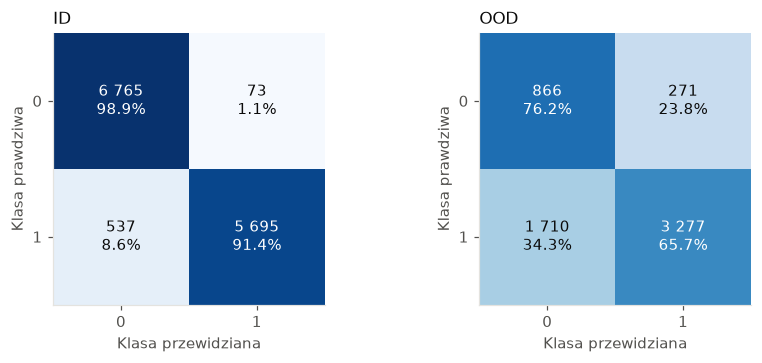

,przewidziane 0,przewidziane 1
prawdziwe 0,6765,73
prawdziwe 1,537,5695


,przewidziane 0,przewidziane 1
prawdziwe 0,866,271
prawdziwe 1,1710,3277


In [8]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

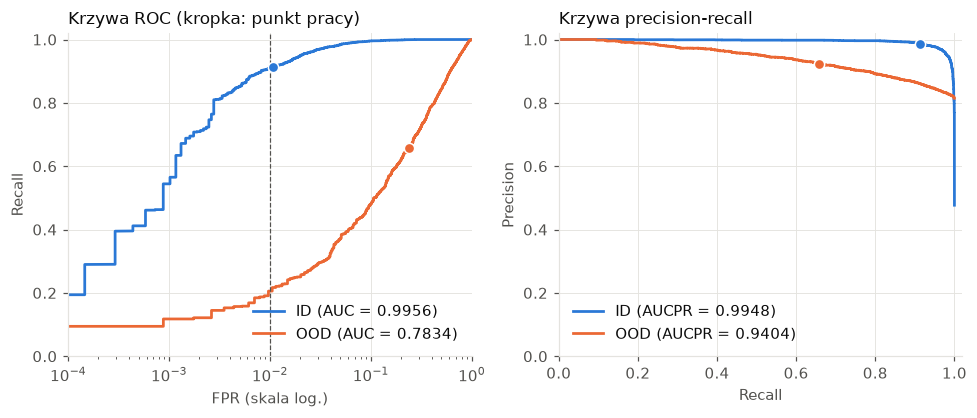

In [9]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")